# Classification Experiments, Version 5
Yang Xiao (yx752)

## Step 0: Data and Baseline
Return to the v3 representation and augmentation. Keep the original 73 numeric features, a 25% flattened-text training weight, seed 27 and the same 8,000/2,000 partition. Compare a small parameter grid and alternative ways to combine the boosting/SVM scores. Selection uses ordinary training OOF AUROC. Formatting sensitivity is reported separately. Dependencies: numpy, pandas, scipy, scikit-learn and matplotlib.

In [1]:
from pathlib import Path
from collections import Counter
import re,json,time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split,StratifiedKFold
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.svm import SVC
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_auc_score,log_loss
SEED=27
paths=[Path('data'),Path('.'),Path('../cornell-tech-cs-5785-combined-2026-ai-vs-human-text')]
DATA=next((p for p in paths if (p/'train.csv').exists()),None)
if DATA is None:raise FileNotFoundError('Place competition CSVs in data/ beside this notebook.')
OUT=Path('v5_results');OUT.mkdir(exist_ok=True)
train=pd.read_csv(DATA/'train.csv');test=pd.read_csv(DATA/'test.csv');sample=pd.read_csv(DATA/'sample_submission.csv')
tr,va=train_test_split(np.arange(len(train)),test_size=2000,stratify=train.label,random_state=SEED)
y=train.label.to_numpy()[tr];yv=train.label.to_numpy()[va]
assert len(tr)==8000 and len(va)==2000
train.iloc[va][['id']].to_csv(OUT/'val_ids.csv',index=False)
print('Train:',len(tr),'Development:',len(va),'Seed:',SEED)

Train: 8000 Development: 2000 Seed: 27


## Step 1: Fixed Features and Augmentation
Feature extraction is unchanged from v3. Each fold fits its model on training originals and canonical copies with weights 0.75 and 0.25. No feature from v4 is added. Copies of held-out rows are never used to fit that fold.

In [2]:
def extract_style_features(text):
    """Return measurable lexical, structural, repetition, and punctuation signals."""
    text = str(text)
    words = re.findall(r"\b[\w']+\b", text.lower())
    word_count = max(len(words), 1)
    sentences = [s for s in re.split(r"(?<=[.!?])\s+|\n+", text.strip()) if s.strip()]
    paragraphs = [p for p in re.split(r"\n\s*\n", text.strip()) if p.strip()]
    sentence_lengths = [len(re.findall(r"\b[\w']+\b", s)) for s in sentences]
    paragraph_lengths = [len(re.findall(r"\b[\w']+\b", p)) for p in paragraphs]
    word_counts = pd.Series(words).value_counts()
    bigrams = list(zip(words, words[1:]))
    bigram_counts = pd.Series(bigrams).value_counts() if bigrams else pd.Series(dtype=int)
    normalized = text.lower()

    def repeat_fraction(counts, total):
        if total == 0 or len(counts) == 0:
            return 0.0
        return float((counts - 1).clip(lower=0).sum() / total)

    def mean(values):
        return float(np.mean(values)) if values else 0.0

    def std(values):
        return float(np.std(values)) if len(values) > 1 else 0.0

    # Candidate discourse templates; counts are normalized per 1,000 words below.
    template_patterns = {
        "not_just_but": r"\bnot just\b.{0,160}\bbut\b",
        "not_only_but_also": r"\bnot only\b.{0,160}\bbut also\b",
        "in_conclusion": r"\bin conclusion\b",
        "it_is_important_to_note": r"\bit is important to note\b",
        "moreover": r"\bmoreover\b",
        "furthermore": r"\bfurthermore\b",
    }
    features = {
        "log_word_count": np.log1p(len(words)),  # Log-scaled number of words.
        "log_character_count": np.log1p(len(text)),  # Log-scaled number of characters, including whitespace.
        "mean_word_length": mean([len(w) for w in words]),  # Average characters per token.
        "word_length_std": std([len(w) for w in words]),  # Variation in token lengths.
        "type_token_ratio": len(set(words)) / word_count,  # Unique words divided by total words; rough lexical diversity.
        "repeated_word_fraction": repeat_fraction(word_counts, len(words)),  # Fraction of word tokens beyond each word's first occurrence.
        "repeated_bigram_fraction": repeat_fraction(bigram_counts, len(bigrams)),  # Fraction of adjacent word-pairs beyond each pair's first occurrence.
        "sentence_count": np.log1p(len(sentences)),  # Log-scaled count of sentence-like spans.
        "mean_sentence_length": mean(sentence_lengths),  # Average words per sentence-like span.
        "sentence_length_std": std(sentence_lengths),  # Spread of sentence lengths.
        "sentence_length_cv": std(sentence_lengths) / max(mean(sentence_lengths), 1.0),  # Sentence-length spread relative to its mean.
        "paragraph_count": np.log1p(len(paragraphs)),  # Log-scaled count of blocks separated by blank lines.
        "mean_paragraph_length": mean(paragraph_lengths),  # Average words per paragraph block.
        "paragraph_length_std": std(paragraph_lengths),  # Spread of paragraph word counts.
        "repeated_sentence_fraction": (len(sentences) - len(set(s.strip().lower() for s in sentences))) / max(len(sentences), 1),  # Share of sentence-like spans duplicated after lowercasing.
        "exclamation_per_100_words": 100 * text.count("!") / word_count,  # Exclamation marks per 100 words.
        "question_per_100_words": 100 * text.count("?") / word_count,  # Question marks per 100 words.
        "comma_per_100_words": 100 * text.count(",") / word_count,  # Commas per 100 words.
        "semicolon_per_100_words": 100 * text.count(";") / word_count,  # Semicolons per 100 words.
        "colon_per_100_words": 100 * text.count(":") / word_count,  # Colons per 100 words.
        "dash_per_100_words": 100 * (text.count("—") + text.count("–")) / word_count,  # Em/en dashes per 100 words.
        "ellipsis_per_100_words": 100 * (text.count("...") + text.count("…")) / word_count,  # Three-dot or single-character ellipses per 100 words.
        "digit_character_fraction": sum(ch.isdigit() for ch in text) / max(len(text), 1),  # Fraction of all characters that are digits.
        "uppercase_character_fraction": sum(ch.isupper() for ch in text) / max(sum(ch.isalpha() for ch in text), 1),  # Fraction of letters that are uppercase.
        "contraction_per_100_words": 100 * len(re.findall(r"\b\w+['’](?:t|re|ve|ll|d|m)\b", normalized)) / word_count,  # Common English contractions per 100 words.
    }
    for name, pattern in template_patterns.items():
        # Frequency of each hypothesized phrase pattern per 1,000 words.
        features[f"template_{name}_per_1000_words"] = 1000 * len(re.findall(pattern, normalized, flags=re.DOTALL)) / word_count
    return features

def expanded_features(text):
    features=extract_style_features(text)
    words=re.findall(r"[a-z]+(?:['’][a-z]+)?",text.lower())
    n=max(len(words),1);nc=max(len(text),1)
    counts=Counter(words)
    values=np.asarray(list(counts.values()),dtype=float)
    lengths=np.asarray([len(w) for w in words],dtype=float)
    sentence_text=[s for s in re.split(r'[.!?]+(?:["\'”’)]*)\s+|\n+',text) if s.strip()]
    sentence_lengths=np.asarray([len(re.findall(r'\b\w+\b',s)) for s in sentence_text],dtype=float)
    for name,array in [('token_length',lengths),('sentence_length',sentence_lengths)]:
        for q in [10,25,50,75,90]:features[f'{name}_q{q}']=float(np.percentile(array,q)) if len(array) else 0.
    features['hapax_ratio']=float(np.sum(values==1)/max(len(values),1))
    features['dislegomena_ratio']=float(np.sum(values==2)/max(len(values),1))
    features['token_entropy']=float(-np.sum((values/n)*np.log(values/n))) if len(values) else 0.
    features['top_token_fraction']=float(values.max()/n) if len(values) else 0.
    features['long_word_fraction']=float(np.mean(lengths>=8)) if len(lengths) else 0.
    features['short_word_fraction']=float(np.mean(lengths<=3)) if len(lengths) else 0.
    groups={
        'first_person':'i me my mine we us our ours',
        'second_person':'you your yours yourself yourselves',
        'third_person':'he him his she her hers they them their theirs',
        'articles':'a an the',
        'prepositions':'of in on at for from to with by about into over under between through',
        'conjunctions':'and or but so because although while whereas if unless since',
        'modals':'can could may might must shall should will would',
        'negations':"no not never neither nor cannot don't doesn't didn't isn't aren't wasn't weren't",
        'demonstratives':'this that these those',
        'be_forms':'am is are was were be been being',
        'have_forms':'have has had having',
    }
    for name,group in groups.items():features[name+'_fraction']=sum(counts[w] for w in group.split())/n
    for char,name in [('"','straight_quote'),("'",'apostrophe'),('(','open_parenthesis'),(')','close_parenthesis'),('[','bracket'),('/','slash'),('-','hyphen'),('%','percent'),(chr(10),'newline')]:
        features[name+'_per_100_words']=100*text.count(char)/n
    features['non_ascii_fraction']=sum(ord(c)>127 for c in text)/nc
    features['whitespace_fraction']=sum(c.isspace() for c in text)/nc
    features['double_space_fraction']=len(re.findall(r' {2,}',text))/nc
    features['sentence_short_fraction']=float(np.mean(sentence_lengths<8)) if len(sentence_lengths) else 0.
    features['sentence_long_fraction']=float(np.mean(sentence_lengths>30)) if len(sentence_lengths) else 0.
    features['list_line_fraction']=len(re.findall(r'(?m)^\s*(?:[-*•]|\d+[.)])\s+',text))/max(len(text.splitlines()),1)
    return features

def canonicalize(text):
    return re.sub(r'\s+',' ',str(text)).translate(str.maketrans({'’':"'",'‘':"'",'“':'"','”':'"','—':'-','–':'-','…':'...'})).strip()

In [3]:
start=time.perf_counter()
raw=pd.DataFrame([expanded_features(str(t)) for t in train.text])
flat=pd.DataFrame([expanded_features(canonicalize(t)) for t in train.text])
z=raw.to_numpy();zf=flat.to_numpy()
assert z.shape[1]==73 and np.isfinite(z).all() and np.isfinite(zf).all()
print('Features:',z.shape[1],'Extraction seconds:',round(time.perf_counter()-start,1))

Features: 73 Extraction seconds: 38.9


## Step 2: Parameter Search on Training Folds
The first two candidates reproduce the selected v3 components. Boosting varies leaves, L2, iteration count and learning rate near the original configuration. RBF SVM varies C=3/10/30 and gamma=scale/0.01. All candidates retain the same augmentation. Three fixed stratified folds produce both raw decision scores and training-distribution percentile scores.

In [4]:
configs=[{'family':'hgb','leaves':31,'l2':1,'iterations':250,'lr':.06},
         {'family':'rbf','C':10,'gamma':'scale'}]
for leaves,l2,iters,lr in [(15,1,250,.06),(15,10,250,.06),(31,10,250,.06),(15,1,400,.04),(31,1,400,.04),(15,.1,250,.06),(31,1,400,.06)]:
    configs.append({'family':'hgb','leaves':leaves,'l2':l2,'iterations':iters,'lr':lr})
for C in [3,10,30]:
    for gamma in ['scale',.01]:
        c={'family':'rbf','C':C,'gamma':gamma}
        if c not in configs:configs.append(c)

def model_for(c):
    if c['family']=='rbf':return make_pipeline(StandardScaler(),SVC(C=c['C'],gamma=c['gamma'],cache_size=512))
    return HistGradientBoostingClassifier(max_iter=c['iterations'],max_leaf_nodes=c['leaves'],l2_regularization=c['l2'],learning_rate=c['lr'],early_stopping=False,random_state=SEED)

def fit_model(c,a,b,labels):
    model=model_for(c);sw=np.concatenate([np.full(len(labels),.75),np.full(len(labels),.25)])
    kwargs={'svc__sample_weight':sw} if hasattr(model,'named_steps') else {'sample_weight':sw}
    return model.fit(np.concatenate([a,b]),np.tile(labels,2),**kwargs)

def score(model,a):return model.decision_function(a)
def rank_score(a,anchors):
    anchors=np.sort(anchors)
    return (np.searchsorted(anchors,a,'left')+np.searchsorted(anchors,a,'right')+1)/(2*(len(anchors)+1))

folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(tr,y))
oof_raw=np.zeros((2,len(tr),len(configs)));oof_rank=np.zeros_like(oof_raw);rows=[]
for j,c in enumerate(configs):
    start=time.perf_counter()
    for a,b in folds:
        model=fit_model(c,z[tr[a]],zf[tr[a]],y[a]);anchors=score(model,z[tr[a]])
        for v,matrix in enumerate([z,zf]):
            values=score(model,matrix[tr[b]])
            oof_raw[v,b,j]=values;oof_rank[v,b,j]=rank_score(values,anchors)
    row={'candidate':j,**c,'ordinary_oof_auroc':roc_auc_score(y,oof_raw[0,:,j]),'flat_oof_auroc':roc_auc_score(y,oof_raw[1,:,j]),'seconds':time.perf_counter()-start}
    rows.append(row);print(j,c,round(row['ordinary_oof_auroc'],6),flush=True)
    pd.DataFrame(rows).to_csv(OUT/'search.csv',index=False)
search=pd.DataFrame(rows).sort_values('ordinary_oof_auroc',ascending=False)
np.savez_compressed(OUT/'oof_scores.npz',raw=oof_raw,rank=oof_rank)
print(search[['candidate','family','ordinary_oof_auroc','flat_oof_auroc']].to_string(index=False))

0 {'family': 'hgb', 'leaves': 31, 'l2': 1, 'iterations': 250, 'lr': 0.06} 0.995948
1 {'family': 'rbf', 'C': 10, 'gamma': 'scale'} 0.992897
2 {'family': 'hgb', 'leaves': 15, 'l2': 1, 'iterations': 250, 'lr': 0.06} 0.996001
3 {'family': 'hgb', 'leaves': 15, 'l2': 10, 'iterations': 250, 'lr': 0.06} 0.995765
4 {'family': 'hgb', 'leaves': 31, 'l2': 10, 'iterations': 250, 'lr': 0.06} 0.995863
5 {'family': 'hgb', 'leaves': 15, 'l2': 1, 'iterations': 400, 'lr': 0.04} 0.996071
6 {'family': 'hgb', 'leaves': 31, 'l2': 1, 'iterations': 400, 'lr': 0.04} 0.996044
7 {'family': 'hgb', 'leaves': 15, 'l2': 0.1, 'iterations': 250, 'lr': 0.06} 0.996091
8 {'family': 'hgb', 'leaves': 31, 'l2': 1, 'iterations': 400, 'lr': 0.06} 0.995877
9 {'family': 'rbf', 'C': 3, 'gamma': 'scale'} 0.993337
10 {'family': 'rbf', 'C': 3, 'gamma': 0.01} 0.993227
11 {'family': 'rbf', 'C': 10, 'gamma': 0.01} 0.993061
12 {'family': 'rbf', 'C': 30, 'gamma': 'scale'} 0.991605
13 {'family': 'rbf', 'C': 30, 'gamma': 0.01} 0.992307
 ca

## Step 3: Isolate the Fusion Change
The exploratory grid shows only a small ordinary-OOF benefit from changing model settings. For the main candidate, retain the exact v3 components and 75% boosting/25% SVM weights, then compare only rank, calibrated-probability and calibrated-logit fusion. Choose the fusion mode using ordinary training OOF AUROC. This isolates one change before modifying the model parameters. Component sigmoid mappings fit training OOF scores with 75% ordinary and 25% flat weight. These OOF labels are also used for fusion selection, so the resulting OOF values are selection scores rather than unbiased estimates. Formatting scores are diagnostic.

In [5]:
def component_calibrators(raw_scores,labels):
    maps={};weights=np.concatenate([np.full(len(labels),.75),np.full(len(labels),.25)])
    for j in range(raw_scores.shape[2]):
        maps[j]=LogisticRegression(C=10,max_iter=1000,random_state=SEED).fit(raw_scores[:,:,j].reshape(-1,1),np.tile(labels,2),sample_weight=weights)
    return maps

def fuse(raw_scores,rank_scores,maps,spec):
    output=np.zeros(raw_scores.shape[:2])
    for j,w in [(spec['hgb'],spec['hgb_weight']),(spec['svm'],1-spec['hgb_weight'])]:
        if spec['mode']=='rank':value=rank_scores[:,:,j]
        elif spec['mode']=='probability':value=maps[j].predict_proba(raw_scores[:,:,j].reshape(-1,1))[:,1].reshape(output.shape)
        else:value=maps[j].decision_function(raw_scores[:,:,j].reshape(-1,1)).reshape(output.shape)
        output+=w*value
    return output

maps=component_calibrators(oof_raw,y)
shortlist=set([0,1]+search.groupby('family',sort=False).head(2).candidate.astype(int).tolist())
hgb_ids=sorted(j for j in shortlist if configs[j]['family']=='hgb')
svm_ids=sorted(j for j in shortlist if configs[j]['family']=='rbf')
specs=[];blend_rows=[]
for a in hgb_ids:
    for b in svm_ids:
        for w in [.5,.75,.9]:
            for mode in ['rank','probability','logit']:
                spec={'hgb':a,'svm':b,'hgb_weight':w,'mode':mode};values=fuse(oof_raw,oof_rank,maps,spec)
                specs.append(spec);blend_rows.append({'blend':len(specs)-1,**spec,'ordinary_oof_auroc':roc_auc_score(y,values[0]),'flat_oof_auroc':roc_auc_score(y,values[1])})
blend_table=pd.DataFrame(blend_rows).sort_values(['ordinary_oof_auroc','blend'],ascending=[False,True])
mode_table=blend_table[(blend_table.hgb==0)&(blend_table.svm==1)&(blend_table.hgb_weight==.75)].sort_values(['ordinary_oof_auroc','blend'],ascending=[False,True])
chosen=specs[int(mode_table.iloc[0].blend)]
print('Fixed-component fusion comparison:')
print(mode_table.to_string(index=False))
baseline={'hgb':0,'svm':1,'hgb_weight':.75,'mode':'rank'}
values=fuse(oof_raw,oof_rank,maps,chosen)
meta_calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(values.reshape(-1,1),np.tile(y,2))
print(blend_table.head(10).to_string(index=False));print('Chosen:',chosen)
print('Baseline ordinary OOF:',roc_auc_score(y,fuse(oof_raw,oof_rank,maps,baseline)[0]))
blend_table.to_csv(OUT/'blend_search.csv',index=False)

Fixed-component fusion comparison:
 blend  hgb  svm  hgb_weight        mode  ordinary_oof_auroc  flat_oof_auroc
     5    0    1        0.75       logit            0.996394        0.957597
     4    0    1        0.75 probability            0.996261        0.957260
     3    0    1        0.75        rank            0.996116        0.952746
 blend  hgb  svm  hgb_weight        mode  ordinary_oof_auroc  flat_oof_auroc
    68    7    9        0.75       logit            0.996526        0.948333
    59    7    1        0.75       logit            0.996525        0.951076
    70    7    9        0.90 probability            0.996514        0.947375
    61    7    1        0.90 probability            0.996507        0.948419
    79    7   10        0.90 probability            0.996496        0.947007
    41    5    9        0.75       logit            0.996490        0.949785
    43    5    9        0.90 probability            0.996489        0.949262
    67    7    9        0.75 probability 

## Step 4: Fixed Development Comparison
Fit the selected and baseline components on the same training partition. Evaluate ordinary text and the flat-format diagnostic on the shared development rows. No new features, extra reflow augmentation or synthetic-stress objective is introduced. The development partition has been inspected across iterations, and all conclusions remain development comparisons.

    view  v3_baseline  v5_selected
Original     0.997979     0.998104
    Flat     0.956759     0.958347
Calibrated original AUROC: 0.9981040000000001


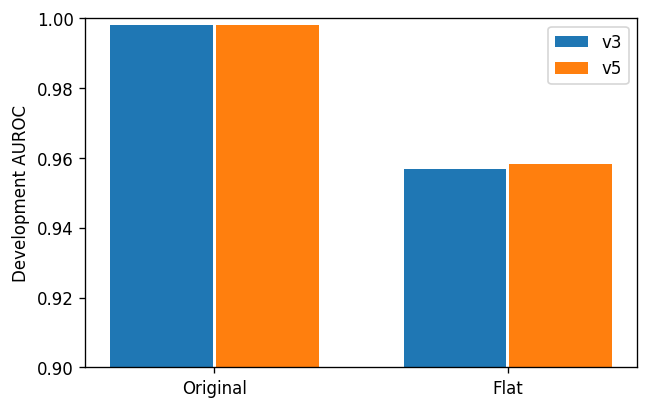

In [6]:
needed=sorted({0,1,chosen['hgb'],chosen['svm']})
dev_raw=np.zeros((2,len(va),len(configs)));dev_rank=np.zeros_like(dev_raw)
for j in needed:
    model=fit_model(configs[j],z[tr],zf[tr],y);anchors=score(model,z[tr])
    for v,matrix in enumerate([z,zf]):
        values=score(model,matrix[va]);dev_raw[v,:,j]=values;dev_rank[v,:,j]=rank_score(values,anchors)
selected_scores=fuse(dev_raw,dev_rank,maps,chosen);baseline_scores=fuse(dev_raw,dev_rank,maps,baseline)
probability=meta_calibrator.predict_proba(selected_scores[0].reshape(-1,1))[:,1]
comparison=pd.DataFrame({'view':['Original','Flat'],'v3_baseline':[roc_auc_score(yv,p) for p in baseline_scores],'v5_selected':[roc_auc_score(yv,p) for p in selected_scores]})
print(comparison.to_string(index=False));print('Calibrated original AUROC:',roc_auc_score(yv,probability))
pd.DataFrame({'id':train.id.to_numpy()[va],'label':yv,'probability':probability}).to_csv(OUT/'validation_predictions.csv',index=False)
comparison.to_csv(OUT/'development_comparison.csv',index=False)
summary={'seed':SEED,'chosen':chosen,'hgb_config':configs[chosen['hgb']],'svm_config':configs[chosen['svm']],'ordinary_oof_auroc':float(mode_table.iloc[0].ordinary_oof_auroc),'development':comparison.to_dict(orient='records'),'probability_development_auroc':roc_auc_score(yv,probability)}
(OUT/'summary.json').write_text(json.dumps(summary,indent=2))
fig,ax=plt.subplots(figsize=(5.5,3.5));pos=np.arange(2)
ax.bar(pos-.18,comparison.v3_baseline,.35,label='v3');ax.bar(pos+.18,comparison.v5_selected,.35,label='v5')
ax.set_xticks(pos,comparison.view);ax.set_ylim(.9,1);ax.set_ylabel('Development AUROC');ax.legend();fig.tight_layout();plt.show()

## Step 5: Full Labeled Refit
Keep settings and fusion fixed. Regenerate OOF raw and percentile scores on all 10,000 labeled rows to fit the component and final sigmoid mappings, then refit the two selected components on all labeled originals plus their formatting copies. Test labels and external labeled data are not used.

In [7]:
yfull=train.label.to_numpy();full_folds=list(StratifiedKFold(n_splits=3,shuffle=True,random_state=SEED).split(train,yfull))
test_z=pd.DataFrame([expanded_features(str(t)) for t in test.text]).to_numpy()
full_raw=np.zeros((2,len(train),len(configs)));full_rank=np.zeros_like(full_raw)
test_raw=np.zeros((1,len(test),len(configs)));test_rank=np.zeros_like(test_raw)
for j in [chosen['hgb'],chosen['svm']]:
    c=configs[j]
    for a,b in full_folds:
        model=fit_model(c,z[a],zf[a],yfull[a]);anchors=score(model,z[a])
        for v,matrix in enumerate([z,zf]):
            values=score(model,matrix[b]);full_raw[v,b,j]=values;full_rank[v,b,j]=rank_score(values,anchors)
    model=fit_model(c,z,zf,yfull);anchors=score(model,z)
    test_raw[0,:,j]=score(model,test_z);test_rank[0,:,j]=rank_score(test_raw[0,:,j],anchors)
    print('Refitted:',j,c,flush=True)
final_maps={};weights=np.concatenate([np.full(len(train),.75),np.full(len(train),.25)])
for j in [chosen['hgb'],chosen['svm']]:
    final_maps[j]=LogisticRegression(C=10,max_iter=1000,random_state=SEED).fit(full_raw[:,:,j].reshape(-1,1),np.tile(yfull,2),sample_weight=weights)
full_scores=fuse(full_raw,full_rank,final_maps,chosen);test_scores=fuse(test_raw,test_rank,final_maps,chosen)
final_calibrator=LogisticRegression(C=100,max_iter=1000,random_state=SEED).fit(full_scores.reshape(-1,1),np.tile(yfull,2))
submission=pd.DataFrame({'id':test.id,'label':final_calibrator.predict_proba(test_scores[0].reshape(-1,1))[:,1]})
submission=submission.set_index('id').loc[sample.id].reset_index()
assert list(submission)==['id','label'] and len(submission)==3000 and submission.id.is_unique
assert submission.id.tolist()==sample.id.tolist() and set(submission.id)==set(test.id)
assert np.isfinite(submission.label).all() and submission.label.between(0,1).all()
submission.to_csv(OUT/'submission_yx752_v5.csv',index=False)
print('Saved 3,000 test probabilities to v5_results/submission_yx752_v5.csv')

Refitted: 0 {'family': 'hgb', 'leaves': 31, 'l2': 1, 'iterations': 250, 'lr': 0.06}
Refitted: 1 {'family': 'rbf', 'C': 10, 'gamma': 'scale'}
Saved 3,000 test probabilities to v5_results/submission_yx752_v5.csv


## Results
The main candidate keeps the v3 73 features, 25% flat-text training weight, boosting configuration (31 leaves, L2=1, 250 iterations, learning rate 0.06), RBF SVM configuration (C=10, gamma=scale), and 75%/25% component weights. The only main change is fusion: component-calibrated logits replace training-distribution percentile scores. Ordinary training OOF AUROC rises from 0.996116 to 0.996394; flat-format OOF AUROC rises from 0.952746 to 0.957597.

On the same development partition, ordinary AUROC changes from 0.9979795 to 0.998104, while flat-format AUROC changes from 0.956759 to 0.958347. The exploratory parameter changes offered only a small additional ordinary OOF gain and were not adopted in the main candidate. These small development gains do not establish a higher public or private test score. V3 remains the scored baseline at 0.97546 public AUROC; the v5 Kaggle score is unknown. The development set has been reused across iterations, and calibration/fusion selection share training OOF labels. Final predictions use a refit and OOF calibration on all 10,000 labeled rows.